<div style="background:#0B1F42;border-radius:14px;padding:28px 32px;color:white;font-family:'Trebuchet MS',sans-serif">
<table style="border:none;background:transparent"><tr style="background:transparent">
<td style="border:none;vertical-align:middle;padding-right:22px">
<img src="https://github.com/doctolib-lab.png?size=160" width="86" style="border-radius:16px;background:white;padding:4px"></td>
<td style="border:none;vertical-align:middle;text-align:left">
<div style="color:#A8C4E0;font-size:14px;letter-spacing:2px">DOCTOLIB LAB · ML4H 2026</div>
<div style="font-size:30px;font-weight:bold;line-height:1.2;margin:6px 0;color:white">DoctoSAE 🔬</div>
<div style="font-size:18px;color:#E8F4FD">Explanations that Transfer: Interpreting Medical Retrieval with Sparse AutoEncoders</div>
</td></tr></table>
<div style="height:4px;background:#107ACA;border-radius:2px;margin:18px 0 14px 0"></div>
<div style="color:#A8C4E0;font-size:14px">Notebook by <b style="color:white">Diane Bouchacourt</b> and <b style="color:white">Gaëtan Brison</b></div>
</div>

<br>

<p align="center">
<a href="https://arxiv.org/abs/2611.18179"><img src="https://img.shields.io/badge/arXiv-2611.18179-b31b1b.svg?logo=arxiv&logoColor=white"></a>
<a href="https://pypi.org/project/doctosae/"><img src="https://img.shields.io/pypi/v/doctosae.svg?color=107ACA"></a>
<a href="https://huggingface.co/collections/doctolib-lab/doctosae"><img src="https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-checkpoints-yellow"></a>
<a href="https://github.com/doctolib-lab/doctosae"><img src="https://img.shields.io/badge/GitHub-doctolib--lab%2Fdoctosae-0B1F42?logo=github"></a>
<a href="https://colab.research.google.com/github/doctolib-lab/doctosae/blob/main/package/examples/doctosae_colab.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg"></a>
</p>

<p align="center"><img src="https://raw.githubusercontent.com/doctolib-lab/doctosae/main/.github/assets/doctosae_overview.png" width="100%"></p>

Dense retrievers are accurate but opaque: nobody can say **why** a passage ranked first. DoctoSAE trains a TopK
**sparse autoencoder** on the frozen embeddings of a text encoder, so that every query and document becomes a
code with at most *k* active features. Documents are ranked by cosine similarity of these codes, and every
feature can be **described** from the texts that fire it.

In this notebook you will, in about 10 minutes on a free Colab GPU:

| | Step | What you get |
| --- | --- | --- |
| 1️⃣ | Load a medical benchmark | NFCorpus, 3,633 nutrition and medicine abstracts |
| 2️⃣ | Embed it with a frozen encoder | `BAAI/bge-large-en-v1.5`, exactly as in the paper |
| 3️⃣ | Load a pretrained DoctoSAE from the Hub | the paper checkpoint `k256_m3072`, trained on CURE |
| 4️⃣ | Look inside a sparse code | 3,072 features, 256 active per text |
| 5️⃣ | Evaluate retrieval | NDCG@10 of the sparse codes, out of domain |
| 6️⃣ | Interpret the features | feature cards with top texts and TF IDF terms |
| 7️⃣ | Explain one retrieval | which features make one passage outrank another |
| 8️⃣ | Search with your own question | ranked passages and the concepts behind them |
| 9️⃣ | Train your own SAE | the paper objective on NFCorpus, in about a minute on a GPU |

<div style="background:#E8F4FD;border:1px solid #107ACA;border-radius:8px;padding:10px 14px;color:#1A1A2E">
💡 <b>Runtime → Change runtime type → T4 GPU</b> before you start. Everything also runs on CPU, but embedding the corpus with BGE large then takes about 15 minutes instead of 1.
</div>

<div style="background:#FEF3C7;border:1px solid #D97706;border-radius:8px;padding:10px 14px;color:#1A1A2E">
⚠️ DoctoSAE is a research tool. Feature descriptions and rankings can be wrong: never use them for diagnosis, treatment or any other clinical decision.
</div>

<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">0</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Install DoctoSAE ⚙️</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">One pip package, on PyPI as <code>doctosae</code>.</div>
</div>

In [ ]:
%pip install -q "doctosae>=0.1.1"

In [ ]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display

import doctosae
from doctosae import (
    DoctoSAE,
    Embedder,
    Interpreter,
    Trainer,
    TrainingConfig,
    evaluate,
    list_pretrained,
    load_dataset,
    load_pretrained,
    search,
)
from doctosae.retrieval import encode_corpus

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.WARNING)

# Doctolib colours
NAVY, BLUE, ICE, OFFWHITE = "#0B1F42", "#107ACA", "#E8F4FD", "#F5F7FA"
TEAL, GOLD, MUTED, DARK = "#0D9488", "#D97706", "#4A5568", "#1A1A2E"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#CBD5E0",
        "axes.labelcolor": DARK,
        "axes.titlecolor": NAVY,
        "axes.titleweight": "bold",
        "axes.titlesize": 13,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "font.family": "DejaVu Sans",
        "legend.frameon": False,
    }
)

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"doctosae {doctosae.__version__} | torch {torch.__version__} | device: {device}")

doctosae 0.1.1 | torch 2.15.0 | device: mps


<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">1</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Load a medical retrieval benchmark 💾</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">Six benchmarks are registered, downloaded from the Hugging Face Hub at pinned revisions with the paper splits.</div>
</div>

In [ ]:
display(pd.DataFrame({"benchmark": doctosae.list_datasets()}))
dataset = load_dataset("nfcorpus")
print(dataset.describe())
dataset.corpus[["text"]].head(3)

,benchmark
0,cure
1,nfcorpus
2,miriad
3,r2med_biology
4,r2med_bioinformatics
5,r2med_medical_sciences


nfcorpus: 3,633 documents | train 2,590 queries / 110,575 judgments | val 324 queries / 11,385 judgments | test 323 queries / 12,334 judgments | license cc-by-sa-4.0


,text
0,Statin Use and Breast Cancer Survival: A Natio...
1,Statin use after diagnosis of breast cancer an...
2,Alkylphenols in human milk and their relations...


<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">2</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Load a pretrained DoctoSAE and its frozen encoder 🤗</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">Every checkpoint records its encoder and query instruction, so <code>Embedder.from_sae</code> rebuilds the exact one.</div>
</div>

In [ ]:
print("Checkpoints of the paper:")
for checkpoint in list_pretrained():
    print("  ", checkpoint)

sae = load_pretrained("bge", k=256)  # doctolib-lab/doctosae-bge-large-en-v1.5/k256_m3072
embedder = Embedder.from_sae(sae, device=device)
print()
print(sae)
print(embedder)

Checkpoints of the paper:


   doctolib-lab/doctosae-bge-large-en-v1.5/k64_m3072
   doctolib-lab/doctosae-bge-large-en-v1.5/k256_m3072
   doctolib-lab/doctosae-gemini-embedding-001/k128_m9216
   doctolib-lab/doctosae-gemini-embedding-001/k256_m9216
   doctolib-lab/doctosae-medembed-large-v0.1/k64_m3072
   doctolib-lab/doctosae-medembed-large-v0.1/k256_m3072



DoctoSAE(
  d_in=1024, n_latents=3072, k=256, activation='relu'
  (encoder): Linear(in_features=1024, out_features=3072, bias=True)
  (decoder): Linear(in_features=3072, out_features=1024, bias=False)
)
Embedder(model='BAAI/bge-large-en-v1.5', query_instruction='Represent this sentence for searching relevant passages: ', device='mps', batch_size=64)


<div style="background:#E8F4FD;border:1px solid #107ACA;border-radius:8px;padding:10px 14px;color:#1A1A2E">
💡 The checkpoint was trained on <b>CURE</b> only. NFCorpus is <b>out of domain</b>: everything below shows how the sparse codes and their explanations <b>transfer</b> to a corpus the SAE never saw.
</div>

In [ ]:
data = embedder.embed_dataset(dataset)  # corpus and queries of every split, float32
print(f"corpus {data.corpus.shape} | test queries {data.queries['test'].shape}")

corpus (3633, 1024) | test queries (323, 1024)


<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">3</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Look inside a sparse code 🔎</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">A dense embedding has 1,024 non zero dimensions; its DoctoSAE code has 3,072 features and exactly k = 256 of them fire.</div>
</div>

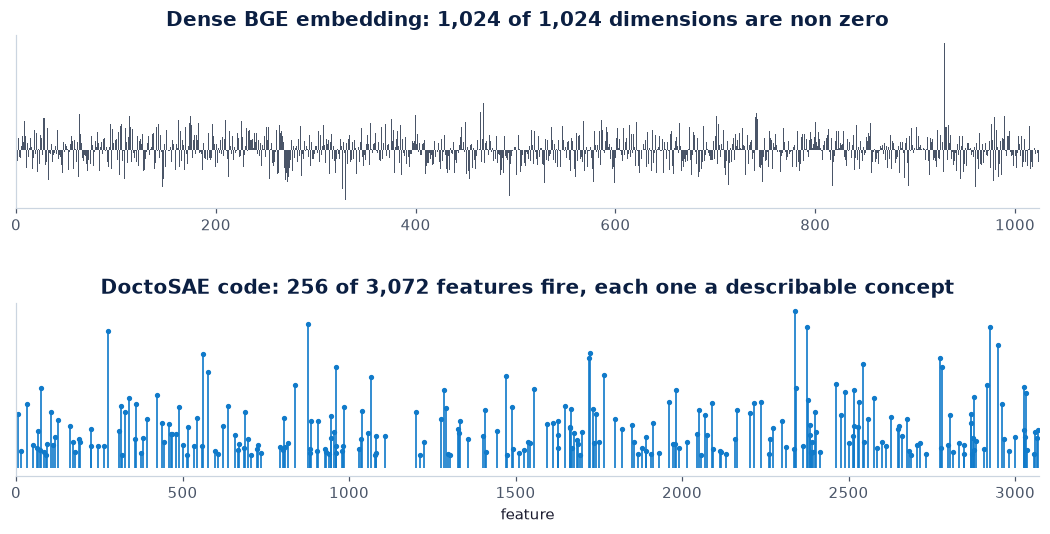

Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific mortality remains uncl ...


In [ ]:
corpus_codes = encode_corpus(sae, data.corpus, device=device)  # sparse CSR matrix, one row per document
doc = 0
dense = data.corpus[doc]
sparse = corpus_codes[doc].toarray().ravel()

fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), gridspec_kw={"hspace": 0.55})
axes[0].bar(np.arange(dense.size), dense, color=MUTED, width=1.0)
axes[0].set_title(
    f"Dense BGE embedding: {np.count_nonzero(dense):,} of {dense.size:,} dimensions are non zero"
)
axes[0].set_xlim(0, dense.size)
active = np.flatnonzero(sparse)
axes[1].vlines(active, 0, sparse[active], color=BLUE, linewidth=1.1)
axes[1].scatter(active, sparse[active], color=BLUE, s=6)
axes[1].set_title(
    f"DoctoSAE code: {active.size} of {sparse.size:,} features fire, each one a describable concept"
)
axes[1].set_xlim(0, sparse.size)
axes[1].set_xlabel("feature")
for ax in axes:
    ax.set_yticks([])
plt.show()
print(dataset.corpus.text.iloc[doc][:300], "...")

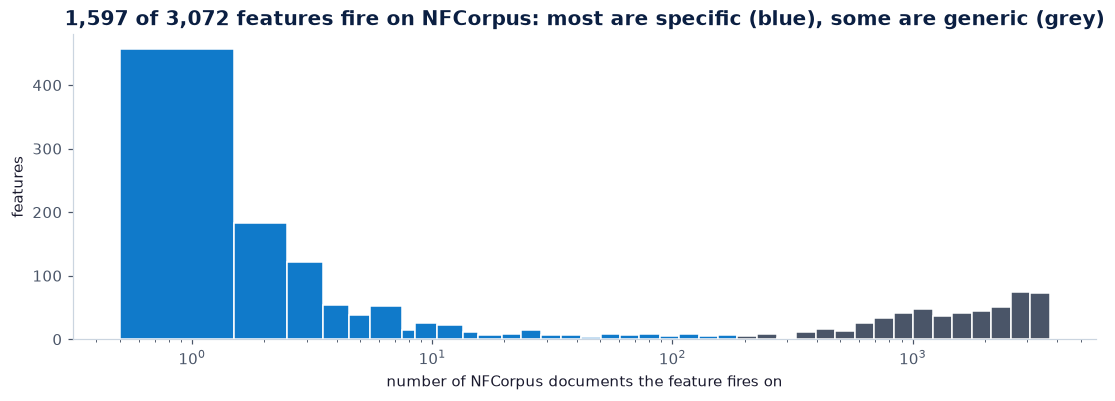

In [ ]:
n_docs = corpus_codes.shape[0]
fires_on = np.asarray((corpus_codes > 0).sum(axis=0)).ravel()  # documents each feature fires on
firing = fires_on / n_docs
edges = np.unique(np.round(np.logspace(0, np.log10(n_docs) + 0.01, 45))) - 0.5
fig, ax = plt.subplots(figsize=(12, 3.6))
counts, bins, patches = ax.hist(fires_on[fires_on > 0], bins=edges, color=BLUE, edgecolor="white")
for patch, left in zip(patches, bins[:-1], strict=True):
    if left > 0.05 * n_docs:
        patch.set_facecolor(MUTED)  # generic features: fire on more than 5% of the corpus
ax.set_xscale("log")
ax.set_xlabel("number of NFCorpus documents the feature fires on")
ax.set_ylabel("features")
ax.set_title(
    f"{(fires_on > 0).sum():,} of {firing.size:,} features fire on NFCorpus: "
    "most are specific (blue), some are generic (grey)"
)
plt.show()

<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">4</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Evaluate retrieval 🎯</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">Every test query ranks the whole corpus by cosine similarity, and NDCG@10 is computed exactly as in the paper.</div>
</div>

In [ ]:
dense_scores = evaluate(None, data, split="test")
sparse_scores = evaluate(sae, data, split="test")
results = pd.DataFrame({"dense BGE embeddings": dense_scores, "DoctoSAE k = 256 (sparse)": sparse_scores}).T
display(results.drop(columns="n_queries").style.format("{:.3f}").background_gradient(cmap="Blues", axis=0))

,ndcg@10,recall@100,mrr@10
dense BGE embeddings,0.382,0.364,0.574
DoctoSAE k = 256 (sparse),0.356,0.338,0.546


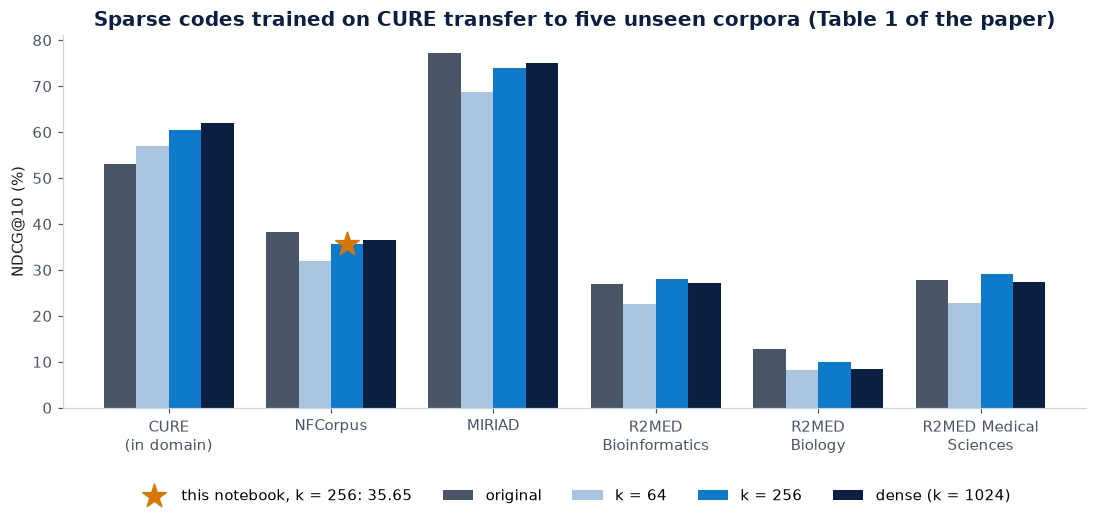

In [ ]:
# Table 1 of the paper: NDCG@10 (%) with BGE large, SAEs trained on CURE only
paper = pd.DataFrame(
    {
        "original": [53.06, 38.17, 77.24, 27.04, 12.72, 27.78],
        "k = 64": [57.07, 31.89, 68.75, 22.50, 8.30, 22.72],
        "k = 256": [60.50, 35.61, 73.85, 28.10, 10.06, 29.05],
        "dense (k = 1024)": [61.87, 36.62, 75.05, 27.21, 8.37, 27.33],
    },
    index=[
        "CURE\n(in domain)",
        "NFCorpus",
        "MIRIAD",
        "R2MED\nBioinformatics",
        "R2MED\nBiology",
        "R2MED Medical\nSciences",
    ],
)
colors = [MUTED, "#A8C4E0", BLUE, NAVY]
ax = paper.plot.bar(figsize=(12, 4.4), color=colors, width=0.8, rot=0)
ax.scatter(
    [1 + 0.1],
    [100 * sparse_scores["ndcg@10"]],
    marker="*",
    s=260,
    color=GOLD,
    zorder=5,
    label=f"this notebook, k = 256: {100 * sparse_scores['ndcg@10']:.2f}",
)
ax.set_ylabel("NDCG@10 (%)")
ax.set_title("Sparse codes trained on CURE transfer to five unseen corpora (Table 1 of the paper)")
ax.legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.show()

Read it this way: in domain (CURE) every sparse model **beats** the original embeddings. Out of domain, the
sparse codes keep most of the dense quality, and on the R2MED corpora, the farthest from CURE, `k = 256`
matches or beats the dense SAE. The gold star is the number this notebook just measured on NFCorpus.

<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">5</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Interpret the features 🧠</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">The Interpreter builds one card per feature: top documents and queries, negatives and TF IDF terms.</div>
</div>

In [ ]:
interpreter = Interpreter(sae, data, split="train")
features = interpreter.select_features(n=6, min_documents=10, min_queries=10, firing_rate_band=(0.005, 0.05))
cards = interpreter.describe(features)  # no LLM: snippets and TF IDF terms only


def chip(text, bg=ICE, fg=NAVY):
    return (
        f'<span style="display:inline-block;background:{bg};color:{fg};border-radius:12px;'
        f'padding:2px 10px;margin:2px;font-size:12px">{text}</span>'
    )


def card_html(card):
    title = card.topic if card.has_label else ", ".join(card.tfidf_terms[:3])
    docs = "".join(
        f'<li style="margin-bottom:4px"><b style="color:{BLUE}">{d["activation"]:.2f}</b> '
        f"{(d.get('title') or d['text'])[:110]}</li>"
        for d in card.top_documents[:3]
    )
    queries = " ".join(chip(q["text"][:40], OFFWHITE, DARK) for q in card.top_queries[:4])
    return f"""
    <div style="flex:1 1 320px;border:1px solid #D6E4F0;border-top:5px solid {BLUE};border-radius:10px;
                padding:12px 14px;margin:6px;background:white;font-family:sans-serif">
      <div style="color:{MUTED};font-size:12px">FEATURE {card.feature} · fires on {card.n_documents} docs
        ({100 * card.firing_rate:.1f}%) and {card.n_queries} queries</div>
      <div style="color:{NAVY};font-weight:bold;font-size:16px;margin:4px 0 6px 0">{title}</div>
      <div>{"".join(chip(t) for t in card.tfidf_terms[:6])}</div>
      <div style="color:{MUTED};font-size:12px;margin-top:8px">TOP DOCUMENTS</div>
      <ol style="padding-left:18px;margin:4px 0;font-size:12.5px;color:{DARK}">{docs}</ol>
      <div style="color:{MUTED};font-size:12px;margin-top:6px">TOP QUERIES</div><div>{queries}</div>
    </div>"""


display(HTML('<div style="display:flex;flex-wrap:wrap">' + "".join(card_html(c) for c in cards) + "</div>"))

<div style="background:#E8F4FD;border:1px solid #107ACA;border-radius:8px;padding:10px 14px;color:#1A1A2E">
💡 Want a written topic for each feature, as in the paper? Set <code>USE_MEDGEMMA = True</code> below. It runs <code>google/medgemma-4b-it</code>, the Interpreter LLM of the paper, on the Colab GPU: accept its terms on the Hugging Face Hub first and log in with <code>huggingface_hub.login()</code>. Any OpenAI compatible server works too, through <code>doctosae.OpenAICompatibleLLM</code>.
</div>

In [ ]:
USE_MEDGEMMA = False

if USE_MEDGEMMA:
    from doctosae import TransformersLLM

    llm = TransformersLLM("google/medgemma-4b-it")
    cards = interpreter.describe(features, llm=llm)
    display(
        HTML('<div style="display:flex;flex-wrap:wrap">' + "".join(card_html(c) for c in cards) + "</div>")
    )
    for card in cards:
        print(f"feature {card.feature}: {card.interpretation}")

<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">6</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Explain one retrieval 💡</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">The cosine of two codes is a sum of one contribution per feature (Figure 2 of the paper).</div>
</div>

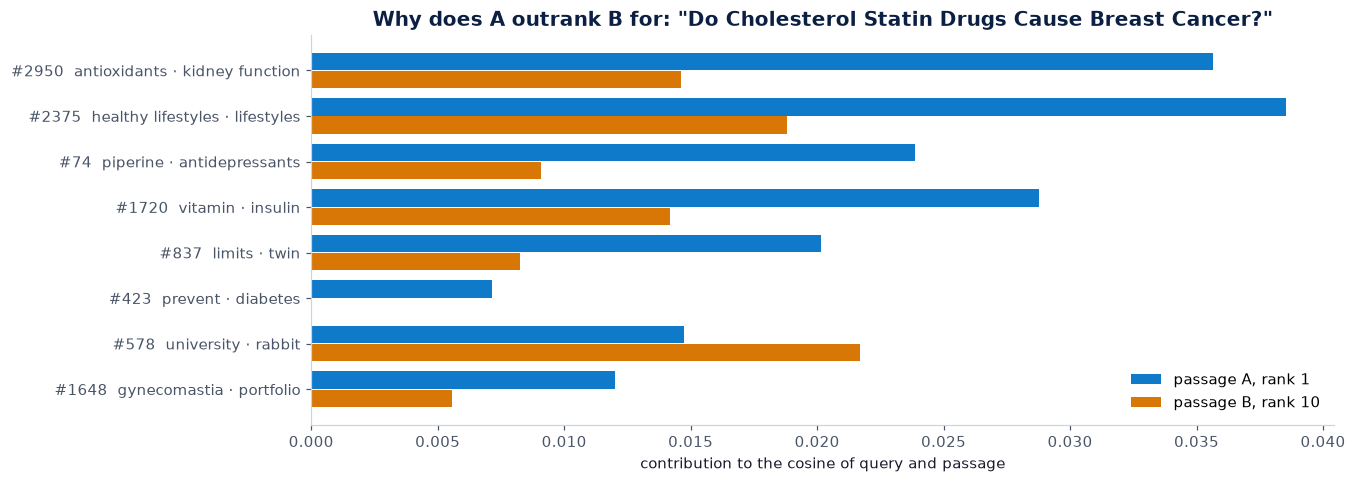

In [ ]:
class FeatureNames(dict):
    """Name of a feature: its LLM topic when labelled, else its two strongest TF IDF terms."""

    def get(self, feature, default=None):
        if feature not in self:
            card = interpreter.describe([int(feature)])[0]
            self[feature] = (
                card.topic if card.has_label else " · ".join(card.tfidf_terms[:2]) or f"#{feature}"
            )
        return self[feature]


names = FeatureNames({c.feature: (c.topic if c.has_label else " · ".join(c.tfidf_terms[:2])) for c in cards})

q = 0
query = dataset.queries["test"].text.iloc[q]
indices, scores = search(sae, data.queries["test"][q : q + 1], data.corpus, top_k=10, device=device)
doc_a, doc_b = (dataset.corpus.text.iloc[i] for i in indices[0, [0, 9]])
explanation = interpreter.explain(query, doc_a, doc_b, n_features=8)

labels = [f"#{f}  {names.get(f, '')}"[:48] for f in explanation.features]
y = np.arange(len(labels))[::-1]
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.barh(
    y + 0.2,
    explanation.contribution_a,
    height=0.38,
    color=BLUE,
    label=f"passage A, rank {explanation.rank_a}",
)
ax.barh(
    y - 0.2,
    explanation.contribution_b,
    height=0.38,
    color=GOLD,
    label=f"passage B, rank {explanation.rank_b}",
)
ax.set_yticks(y, labels)
ax.set_xlabel("contribution to the cosine of query and passage")
ax.set_title(f'Why does A outrank B for: "{query[:70]}"')
ax.legend(loc="lower right")
plt.show()

display(
    HTML(f"""
<div style="font-family:sans-serif;font-size:13px;color:{DARK}">
<p><b style="color:{NAVY}">Query:</b> {query}</p>
<p><b style="color:{BLUE}">A (rank {explanation.rank_a}, cosine {explanation.cosine_a:.3f}):</b>
{explanation.passage_a[:300]}...</p>
<p><b style="color:{GOLD}">B (rank {explanation.rank_b}, cosine {explanation.cosine_b:.3f}):</b>
{explanation.passage_b[:300]}...</p>
</div>""")
)

Each bar is one feature's share of the cosine. Features are named here by their two strongest TF IDF terms on
NFCorpus, a rough name for a checkpoint trained on another corpus; generic features, which fire on most
documents, get the least telling names. Set `USE_MEDGEMMA = True` in section 5 for a written topic per feature,
as in Figure 2 of the paper.

<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">7</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Search with your own question 🔍</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">Your question is embedded with the same encoder, encoded by the SAE and matched against the corpus.</div>
</div>

In [ ]:
def ask(question, top_k=5):
    q_emb = embedder.encode_queries([question])
    q_code = encode_corpus(sae, q_emb, device=device)
    idx, sc = search(sae, q_emb, data.corpus, top_k=top_k, device=device)
    ranked = q_code.indices[np.argsort(-q_code.data)]
    q_feats = [f for f in ranked if 0 < firing[f] < 0.05][:6]  # the strongest topic specific features
    concepts = "".join(chip(names.get(f, f"#{f}")) for f in q_feats)
    rows = ""
    for rank, (i, s) in enumerate(zip(idx[0], sc[0], strict=True), start=1):
        row = corpus_codes[i].toarray().ravel()
        shared = [f for f in q_feats if row[f] > 0]
        rows += (
            f'<tr><td style="color:{BLUE};font-weight:bold">{rank}</td><td>{s:.3f}</td>'
            f'<td style="text-align:left">{dataset.corpus.text.iloc[i][:160]}...<br>'
            f"{''.join(chip(names.get(f, f'#{f}'), OFFWHITE, MUTED) for f in shared)}</td></tr>"
        )
    display(
        HTML(f"""
    <div style="font-family:sans-serif">
    <div style="color:{NAVY};font-size:16px;font-weight:bold">🔍 {question}</div>
    <div style="margin:6px 0 10px 0;color:{MUTED};font-size:12px">
    STRONGEST TOPIC SPECIFIC FEATURES {concepts}</div>
    <table style="font-size:13px">
    <tr><th>#</th><th>cosine</th><th style="text-align:left">passage and shared concepts</th></tr>
    {rows}</table></div>""")
    )


ask("Does eating red meat increase the risk of colon cancer?")

#,cosine,passage and shared concepts
1,0.719,"Red meat and colon cancer: should we become vegetarians, or can we make meat safer? The effect of meat consumption on cancer risk is a controversial issue. Howe..."
2,0.703,Red and Processed Meat and Colorectal Cancer Incidence: Meta-Analysis of Prospective Studies Background The evidence that red and processed meat influences colo...
3,0.684,Red meat consumption and cancer: reasons to suspect involvement of bovine infectious factors in colorectal cancer. An increased risk for colorectal cancer has b...
4,0.683,"Dietary risk factors for colon cancer in a low-risk population. In a 6-year prospective study, the authors examined the relation between diet and incident colon..."
5,0.680,Processed meat and colorectal cancer: a review of epidemiologic and experimental evidence Processed meat intake may be involved in the etiology of colorectal ca...


In [ ]:
ask("Can vitamin D supplements prevent the flu?")  # try your own question

#,cosine,passage and shared concepts
1,0.569,"Old wine in new bottles: vitamin D in the treatment and prevention of tuberculosis. Tuberculosis (TB) is a major cause of mortality, responsible for 1·68 millio...athletes · performance"
2,0.569,Vitamin D in the treatment of pulmonary tuberculosis. Vitamin D was used to treat tuberculosis in the pre-antibiotic era. New insights into the immunomodulatory...
3,0.559,Vitamin D supplementation for prevention of mortality in adults. BACKGROUND: The available evidence on vitamin D and mortality is inconclusive. OBJECTIVES: To a...alkaline · obesity
4,0.535,Vitamin D(3) is more potent than vitamin D(2) in humans. BACKGROUND: Current unitage for the calciferols suggests that equimolar quantities of vitamins D(2) (D2...vitamin · strength
5,0.534,Taking vitamin D with the largest meal improves absorption and results in higher serum levels of 25-hydroxyvitamin D. Many patients treated for vitamin D defici...


The chips under a passage are the topic specific features it shares with your question. On NFCorpus, a corpus
this checkpoint never saw, most of the score comes from broad features that fire on many passages, so few topic
specific ones are shared and their TF IDF names stay rough. Train on your own corpus (section 8) or label the
features with MedGemma (section 5) for sharper concepts.

<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">8</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Train your own DoctoSAE 🏋️</span>
<div style="color:#4A5568;font-size:14px;margin-top:4px">The paper objective: reconstruction plus an InfoNCE loss that pulls queries towards their relevant documents.</div>
</div>

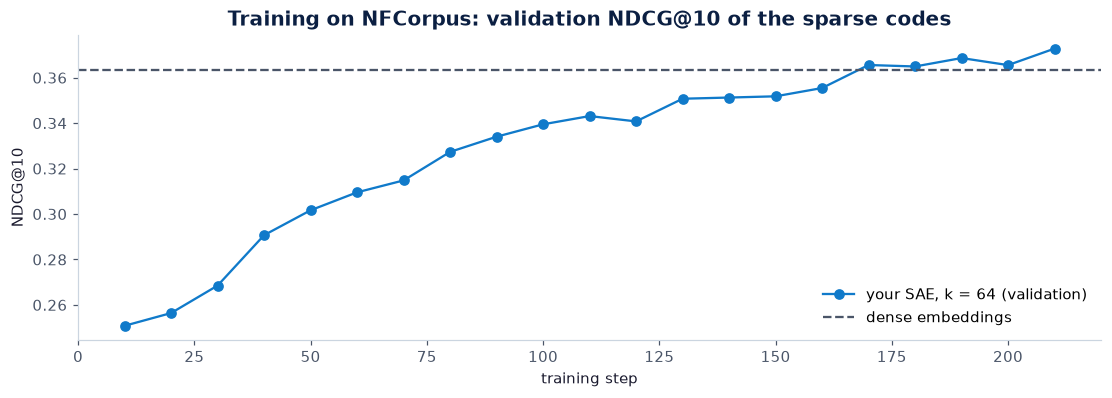

,ndcg@10,recall@100,mrr@10
dense BGE embeddings,0.382,0.364,0.574
"pretrained on CURE, k = 256",0.356,0.338,0.546
"trained here on NFCorpus, k = 64",0.391,0.418,0.558


In [ ]:
torch.manual_seed(42)
my_sae = DoctoSAE(d_in=data.dim, n_latents=3 * data.dim, k=64, embedder=data.embedder)
config = TrainingConfig(
    epochs=30, eval_every=10, device=device
)  # the paper trains 100 epochs; 30 keep this demo short
trainer = Trainer(my_sae, config, output_dir="runs/nfcorpus/sae").fit(data)
my_sae = trainer.best_model

history = pd.DataFrame(trainer.history)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(
    history["step"], history["val_ndcg@10"], color=BLUE, marker="o", label="your SAE, k = 64 (validation)"
)
ax.axhline(
    evaluate(None, data, split="val")["ndcg@10"], color=MUTED, linestyle="--", label="dense embeddings"
)
ax.set_xlabel("training step")
ax.set_ylabel("NDCG@10")
ax.set_title("Training on NFCorpus: validation NDCG@10 of the sparse codes")
ax.legend()
plt.show()

comparison = pd.DataFrame(
    {
        "dense BGE embeddings": dense_scores,
        "pretrained on CURE, k = 256": sparse_scores,
        "trained here on NFCorpus, k = 64": evaluate(my_sae, data, split="test"),
    }
).T
display(comparison.drop(columns="n_queries").style.format("{:.3f}").background_gradient(cmap="Blues", axis=0))

<div style="background:#E8F4FD;border:1px solid #107ACA;border-radius:8px;padding:10px 14px;color:#1A1A2E">
💡 Trained in domain with only 64 active features, the SAE can beat the dense embeddings it was built from. <code>my_sae.push_to_hub('your-name/doctosae-nfcorpus-k64')</code> or <code>doctosae push</code> shares it, private by default.
</div>

<div style="border-left:6px solid #107ACA;background:#F5F7FA;padding:12px 18px;border-radius:6px">
<span style="display:inline-block;background:#107ACA;color:white;border-radius:50%;width:30px;height:30px;
text-align:center;line-height:30px;font-weight:bold;margin-right:10px">✓</span>
<span style="color:#0B1F42;font-size:21px;font-weight:bold;font-family:'Trebuchet MS',sans-serif">Where to go next 🚀</span>

</div>

* 📄 **Paper**: [arXiv 2611.18179](https://arxiv.org/abs/2611.18179), ML4H 2026
* 📦 **Package**: `pip install doctosae`, the full API and the `doctosae` command line in the [README](https://github.com/doctolib-lab/doctosae)
* 🤗 **Checkpoints**: BGE, MedEmbed and Gemini SAEs in the [DoctoSAE collection](https://huggingface.co/collections/doctolib-lab/doctosae)
* 🧪 **Reproduce the paper**: [`paper/`](https://github.com/doctolib-lab/doctosae/tree/main/paper) holds the exact code behind every table
* 🩺 **Annotation app**: the Streamlit app used with clinicians, in [`annotation_app/`](https://github.com/doctolib-lab/doctosae/tree/main/annotation_app)

```bibtex
@misc{bouchacourt2026explanationstransferinterpretingmedical,
      title={Explanations that Transfer: Interpreting Medical Retrieval with Sparse AutoEncoders},
      author={Diane Bouchacourt and Gaëtan Brison},
      year={2026},
      eprint={2611.18179},
      archivePrefix={arXiv},
      primaryClass={cs.IR},
      url={https://arxiv.org/abs/2611.18179},
}
```

<div style="background:#0B1F42;border-radius:12px;padding:18px 24px;color:white;text-align:center;font-family:'Trebuchet MS',sans-serif">
<div style="font-size:22px;font-weight:bold">Congrats, you made it 🎉</div>
<div style="color:#A8C4E0;margin-top:6px">If DoctoSAE helps your work, a ⭐ on <a style="color:#E8F4FD" href="https://github.com/doctolib-lab/doctosae">GitHub</a> helps us a lot.</div>
</div>